**SAPIANS** · SCC5819 · MÓDULO 09 — DECOMPOSIÇÃO FUNCIONAL · MOLNAR, CAP. 22

# Decompor a superfície de PD sob pesos explícitos

H resumia um desvio em relação à soma de dependências parciais. Agora fixamos
a superfície de idade e saturação e uma medida produto para identificar
intercepto, efeitos principais e interação.

[README do módulo](../README.md) · [outline da aula](../lecture/outline.md) · [Colab](https://colab.research.google.com/github/wbendinelli/interpretable-ml-lectures/blob/main/modules/09-functional-decomposition/notebooks/decomposition_walkthrough.ipynb)

---

**Objetivos.** Declarar a superfície discretizada e seus pesos; calcular
componentes com médias condicionais nulas; conferir reconstrução e identidade
de variâncias; examinar como a referência e a grade redistribuem os componentes.

In [1]:
%pip install -q numpy pandas pyarrow scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib
import inspect
import itertools
import os
import pathlib
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import log_loss
from xgboost import XGBClassifier

RANDOM_STATE = 42
REPO = pathlib.Path(
    os.environ.get("INTERPRETABLE_ML_REPO", pathlib.Path.cwd())
).resolve()
while REPO != REPO.parent and not (REPO / "tools/README.md").exists():
    REPO = REPO.parent
if not (REPO / "tools/README.md").exists():
    REPO = pathlib.Path(tempfile.gettempdir()) / "interpretable-ml-lectures"
    if not REPO.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "--depth",
                "1",
                "https://github.com/wbendinelli/interpretable-ml-lectures.git",
                str(REPO),
            ],
            check=True,
            capture_output=True,
        )
sys.path.insert(0, str(REPO / "tools"))
import sapians as SP
import srag_60_model as M
import srag_71_global_effects as G

# Tudo que é gerado fica fora da árvore de trabalho; só cópias explícitas são publicadas.
WORK = pathlib.Path(
    os.environ.get("GLOBAL_EFFECTS_WORK", tempfile.mkdtemp(prefix="global-effects-"))
)
os.chdir(WORK)
SP.aplicar(tema="global")
print("Perfil visual: SAPIANS Global / VITA | fonte:", SP.FONTE_ATUAL)

Perfil visual: SAPIANS Global / VITA | fonte: Satoshi


## §1 — Mesmo dado, mesmo preditor, pergunta global

A amostra Gold do módulo da base e a receita histórica são reutilizadas sem seleção ou balanceamento adicional. A ordem por identificador precede o sorteio; o alvo não orienta a escolha das fichas. O fundo integra as outras entradas. Painel e fundo são amostras de explicação do teste temporal, não novas partições para selecionar modelos.

In [3]:
path = REPO / "modules/00-dataset/gold/gold_covid_obito_sample.parquet"
gold = M.load_gold(path)
x, _, y = M.design_matrix(gold)
tr = (gold["split"] == "train").to_numpy()
te = (gold["split"] == "test").to_numpy()
model = XGBClassifier(**M.XGB_PARAMS).fit(x.loc[tr], y[tr])
model_bytes = bytes(model.get_booster().save_raw())


def prever(frame):
    return np.asarray(model.predict_proba(frame[list(M.FEATURES)])[:, 1], dtype=float)


teste = gold.loc[te].sort_values("gold_id").reset_index(drop=True)
# Sorteio independente do alvo, do erro e da magnitude dos efeitos.
painel = teste.sample(n=512, random_state=RANDOM_STATE).reset_index(drop=True)
fundo = painel.iloc[:256].copy()
xf = M.design_matrix(fundo)[0]
xp = M.design_matrix(painel)[0]
original_xf = xf.copy(deep=True)
print("SHA256 da amostra:", hashlib.sha256(path.read_bytes()).hexdigest())
print("SHA256 do preditor desta execução:", hashlib.sha256(model_bytes).hexdigest())
print("Semente:", SP.pt_int(RANDOM_STATE))
print("Treino até:", str(2022), "| validação:", str(2023), "| teste:", str(2024))
print(
    "Treino:",
    SP.pt_int(tr.sum()),
    "| validação:",
    SP.pt_int((gold["split"] == "val").sum()),
)
print("Teste completo:", SP.pt_int(te.sum()), "| óbitos:", SP.pt_int(y[te].sum()))
print(
    "Entradas:",
    SP.pt_int(len(M.FEATURES)),
    "| painel:",
    SP.pt_int(len(painel)),
    "| fundo:",
    SP.pt_int(len(fundo)),
)
print("Log loss do teste completo:", SP.pt(log_loss(y[te], prever(x.loc[te])), 6))
print("Previsão média no painel:", SP.pct(prever(xp).mean()))
print(
    "Versões:",
    "Python",
    sys.version.split()[0],
    "| numpy",
    np.__version__,
    "| pandas",
    pd.__version__,
)
print("Alvo não participa das curvas; teste já observado, análise exploratória.")

SHA256 da amostra: cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918
SHA256 do preditor desta execução: 55b1c49045b8b6368d61eb91073beaaf6197c0081613ad688670eaefe5e91007
Semente: 42
Treino até: 2022 | validação: 2023 | teste: 2024
Treino: 200.000 | validação: 24.148
Teste completo: 16.142 | óbitos: 2.945
Entradas: 40 | painel: 512 | fundo: 256
Log loss do teste completo: 0,409020
Previsão média no painel: 21,9%
Versões: Python 3.12.13 | numpy 2.4.6 | pandas 2.3.3
Alvo não participa das curvas; teste já observado, análise exploratória.


**O que olhar.**

- Os tamanhos impressos distinguem o treino do modelo, o teste completo e o orçamento da explicação.
- O log loss identifica o preditor; as curvas abaixo descrevem suas previsões, sem estimar efeitos clínicos.

## §2 — Escolher a função e a medida de referência

Nossa função é a PD conjunta de idade e saturação: as demais entradas são integradas sobre o fundo. Não é o preditor completo. Discretizamos idade por medianas de grupos de quantis e usamos os pesos marginais do painel. A medida produto é uma referência artificial que rompe a dependência idade–saturação. Sob ela, $f_0=E[f]$, $f_j=E_k[f]-f_0$, $f_k=E_j[f]-f_0$ e $f_{jk}=f-f_0-f_j-f_k$.

In [4]:
print(inspect.getsource(G.decompor_superficie))

# Grade e pesos definidos antes de inspecionar a superfície.
faixas = pd.qcut(painel["idade_anos"], q=8, duplicates="drop")
resumo_idade = painel.groupby(faixas, observed=True)["idade_anos"].agg(
    ["median", "size"]
)
idades = resumo_idade["median"].to_numpy()
wj = resumo_idade["size"].to_numpy(dtype=float)
estados = list(xf["saturacao"].cat.categories)
wk = (
    painel["saturacao"]
    .value_counts()
    .reindex(estados, fill_value=0)
    .to_numpy(dtype=float)
)
pontos = pd.DataFrame(
    itertools.product(idades, estados), columns=["idade_anos", "saturacao"]
)
superficie = G.pd_empirica(prever, xf, pontos).reshape(len(idades), len(estados))
dec = G.decompor_superficie(superficie, wj, wk)
recon_error = np.max(np.abs(superficie - dec["reconstrucao"]))
assert recon_error < 1e-12
assert np.isclose(dec["variancias"].sum(), dec["total"], atol=1e-14)
print(
    "Idades representativas:",
    SP.pt_int(len(idades)),
    "| estados:",
    SP.pt_int(len(estados)),
)
print("Intercepto da superfície:", SP.pt(dec["f0"], 6))
print("Erro máximo de reconstrução:", SP.pt_sig(recon_error, 4))
print("Soma das variâncias:", SP.pt(dec["variancias"].sum(), 10))
print("Variância da superfície sob o produto:", SP.pt(dec["total"], 10))
partes = pd.DataFrame(
    {
        "componente": ["idade", "saturação", "interação"],
        "variância": dec["variancias"],
        "fração no produto": dec["variancias"] / dec["total"],
    }
)
print(SP.tabela(partes, casas=6))
print("Pesos da idade:", ", ".join(SP.pt(v, 4) for v in dec["pesos_j"]))
print("Pesos da saturação:", ", ".join(SP.pt(v, 4) for v in dec["pesos_k"]))

def decompor_superficie(superficie, pesos_j, pesos_k) -> dict:
    """Decomposição ANOVA de uma tabela sob a medida produto declarada.

    A tabela pode ser a PD de um par num modelo maior: nesse caso decompomos
    apenas essa superfície marginalizada, não todas as entradas do preditor.
    Ortogonalidade e parcelas de variância valem sob w_j ⊗ w_k, que não é a
    distribuição conjunta observada de pacientes com entradas dependentes.
    """
    s = np.asarray(superficie, dtype=float)
    wj, wk = np.asarray(pesos_j, float), np.asarray(pesos_k, float)
    if (
        s.ndim != 2
        or wj.ndim != 1
        or wk.ndim != 1
        or s.shape != (len(wj), len(wk))
        or not all(np.isfinite(v).all() for v in (s, wj, wk))
        or (wj < 0).any()
        or (wk < 0).any()
        or wj.sum() <= 0
        or wk.sum() <= 0
    ):
        raise ValueError("Superfície e pesos finitos, não negativos e compatíveis.")
    wj, wk = wj / wj.sum(), wk / wk.sum()
    produto = np.outer(

Idades representativas: 8 | estados: 3
Intercepto da superfície: 0,220314
Erro máximo de reconstrução: 0,0000
Soma das variâncias: 0,0122997211
Variância da superfície sob o produto: 0,0122997211
componente variância fração no produto
     idade  0,010524          0,855655
 saturação  0,001587          0,129004
 interação  0,000189          0,015341
Pesos da idade: 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250, 0,1250
Pesos da saturação: 0,1348, 0,2246, 0,6406


**O que olhar.**

- O erro de reconstrução verifica a identidade na grade, não a fidelidade de uma aproximação ao preditor completo.
- As frações de variância impressas pertencem somente à superfície e à medida produto declarada.

## §3 — Reconstruir com intercepto, efeitos principais e interação

Exibimos a superfície e os componentes na mesma grade. A interação é o que resta após remover intercepto e os efeitos principais definidos pela medida produto.

figura: figures_generated/decomposition-componentes.png


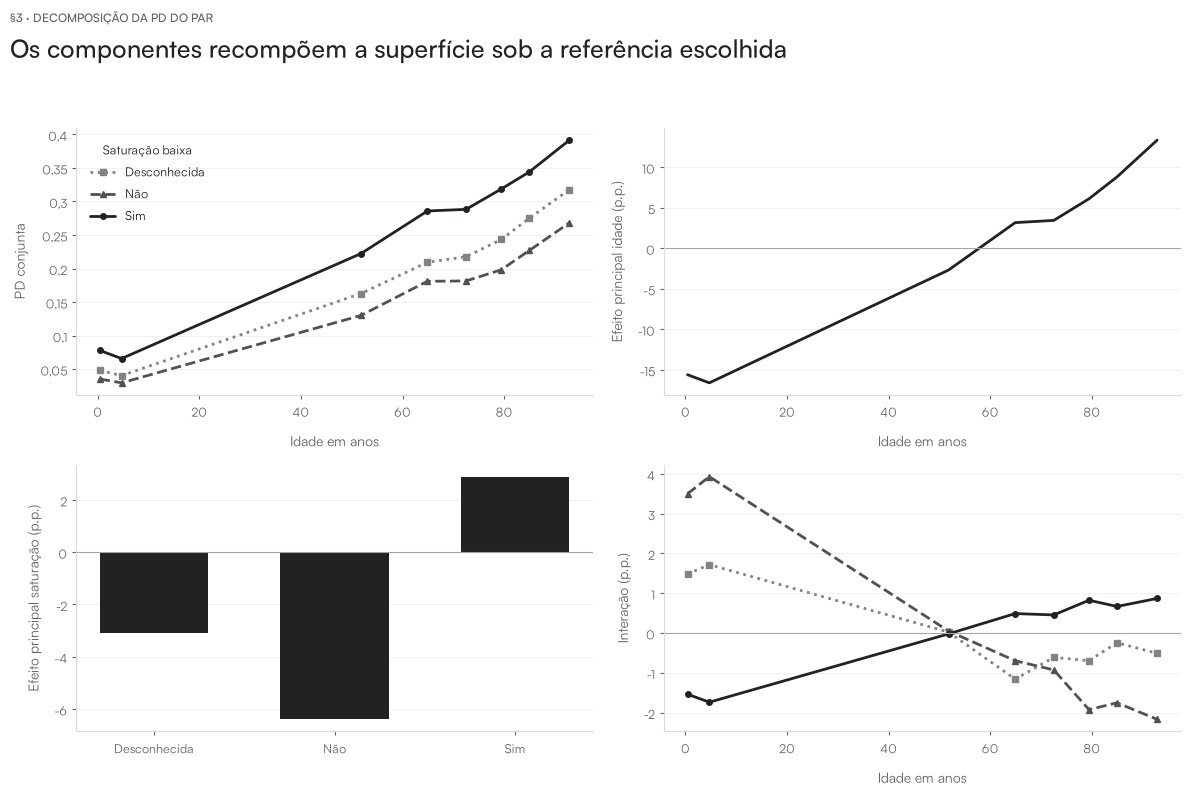

In [5]:
fig, axes = plt.subplots(2, 2, figsize=SP.PAINEL)
rotulos = {"desconhecido": "Desconhecida", "nao": "Não", "sim": "Sim"}
for k, estado in enumerate(estados):
    axes[0, 0].plot(
        idades,
        superficie[:, k],
        label=rotulos[estado],
        color=SP.rampa(len(estados), lo=0.5)[k],
        linestyle=[":", "--", "-"][k],
        marker=["s", "^", "o"][k],
        markersize=4,
    )
    axes[1, 1].plot(
        idades,
        100 * dec["fjk"][:, k],
        label=rotulos[estado],
        color=SP.rampa(len(estados), lo=0.5)[k],
        linestyle=[":", "--", "-"][k],
        marker=["s", "^", "o"][k],
        markersize=4,
    )
axes[0, 0].set(ylabel="PD conjunta", xlabel="Idade em anos")
axes[0, 0].legend(title="Saturação baixa")
axes[0, 1].plot(idades, 100 * dec["fj"], color=SP.ESCURO)
axes[0, 1].set(ylabel="Efeito principal idade (p.p.)", xlabel="Idade em anos")
axes[1, 0].bar(
    [rotulos[e] for e in estados], 100 * dec["fk"], color=SP.ESCURO, width=0.6
)
axes[1, 0].set(ylabel="Efeito principal saturação (p.p.)")
axes[1, 1].set(ylabel="Interação (p.p.)", xlabel="Idade em anos")
for ax in [axes[0, 1], axes[1, 0], axes[1, 1]]:
    ax.axhline(0, color=SP.CINZA_CLARO, linewidth=0.8)
SP.titulo(
    fig,
    "Os componentes recompõem a superfície sob a referência escolhida",
    "§3 · Decomposição da PD do par",
)
SP.salvar(fig, "decomposition-componentes")
plt.show()

**O que olhar.**

- O intercepto foi impresso na seção anterior; ele se soma aos componentes centralizados.
- As curvas recompõem valores da grade. A discretização não resolve as previsões entre esses pontos.

## §4 — Mudar a referência redistribui os componentes

Mantemos a superfície, mas atribuímos pesos uniformes aos estados e idades. O intercepto e as parcelas podem mudar, mesmo com reconstrução exata. Isso demonstra por que o condicionamento não é um detalhe.

In [6]:
uniforme = G.decompor_superficie(
    superficie, np.ones(len(idades)), np.ones(len(estados))
)
rows = []
for label, d in [("Produto das marginais", dec), ("Produto uniforme", uniforme)]:
    rows.append(
        {
            "referência": label,
            "intercepto": d["f0"],
            "variância total": d["total"],
            "fração interação": d["variancias"][2] / d["total"],
            "erro reconstrução": np.max(np.abs(d["reconstrucao"] - superficie)),
        }
    )
print(SP.tabela(pd.DataFrame(rows), casas=8))
# Frequências conjuntas reais: diagnóstico de quanto o produto se afasta do painel.
cont = pd.crosstab(faixas, painel["saturacao"], dropna=False).reindex(
    columns=estados, fill_value=0
)
observada = cont.to_numpy() / cont.to_numpy().sum()
produto = np.outer(dec["pesos_j"], dec["pesos_k"])
print(
    "Distância de variação total conjunta vs produto:",
    SP.pt(0.5 * np.abs(observada - produto).sum(), 6),
)
print(
    "Covariância dos efeitos principais na conjunta discretizada:",
    SP.pt(np.sum(observada * dec["fj"][:, None] * dec["fk"][None, :]), 10),
)
print("Não usamos parcelas produto para explicar a variância da coorte observada.")

           referência intercepto variância total fração interação erro reconstrução
Produto das marginais 0,22031385      0,01229972       0,01534107        0,00000000
     Produto uniforme 0,19829438      0,01078857       0,01665946        0,00000000
Distância de variação total conjunta vs produto: 0,072266
Covariância dos efeitos principais na conjunta discretizada: 0,0000639080
Não usamos parcelas produto para explicar a variância da coorte observada.


**O que olhar.**

- A distância impressa compara distribuições discretizadas, sem testar independência populacional.
- A ortogonalidade sob o produto não é transferível automaticamente à distribuição conjunta observada.

### O que o livro diz

O [capítulo de Molnar](https://christophm.github.io/interpretable-ml-book/decomposition.html)
exige regras que identifiquem os componentes de uma decomposição. A aplicação
aqui usa médias e projeções quadráticas ponderadas de uma superfície de PD
discretizada, sob o produto explícito das marginais do painel.

Essa referência permite conferir centralização, ortogonalidade e reconstrução
na grade. Ela não é a distribuição conjunta observada nem uma decomposição
do preditor completo. O exemplo inicial do livro usa ALE; nossa aplicação
escolhe a decomposição produto e não implementa a extensão geral para entradas
dependentes. As parcelas não identificam efeitos clínicos.

## §5 — Auditoria da base e da amostra de explicação

A referência é a amostra Gold commitada do projeto, não a extração bruta inteira do SIVEP-Gripe. Conferimos sua integridade e comparamos o painel com o teste temporal completo. As distribuições descritivas abaixo não demonstram representatividade populacional. O desfecho entra apenas nesta descrição posterior ao sorteio, nunca na construção das curvas.

O livro e o pacote foram inspecionados em revisões fixadas: [fonte do livro](https://github.com/christophM/interpretable-ml-book/tree/8f470c85e5ed4ebd69de74425cb9832f1bdc25eb) e [fonte de iml](https://github.com/giuseppec/iml/tree/4818c8f81dea2e76318857fbc3d50bc78cdd22f6). A avaliação distingue fórmula, configuração numérica, aplicação na base e alcance da interpretação. Não executamos o pacote R: as conferências de seu algoritmo são traduções explícitas para Python, identificadas nos internals.


In [7]:
from scipy.stats import ks_2samp

amostra_sha = hashlib.sha256(path.read_bytes()).hexdigest()
assert amostra_sha == "cb79c99338a5a7b3c125659aad148a73749e2695f2048c9481a20ab29e3ca918"
assert gold["gold_id"].is_unique
assert not set(gold.loc[tr, "gold_id"]) & set(teste["gold_id"])
linhas = []
for nome, base in [("Teste temporal", teste), ("Painel", painel), ("Fundo", fundo)]:
    xx, _, yy = M.design_matrix(base)
    linhas.append(
        {
            "referência": nome,
            "fichas": len(base),
            "óbitos observados": int(yy.sum()),
            "fração óbito": yy.mean(),
            "previsão média": prever(xx).mean(),
            "idade p10": base["idade_anos"].quantile(0.1),
            "idade mediana": base["idade_anos"].median(),
            "idade p90": base["idade_anos"].quantile(0.9),
            "saturação sim": (base["saturacao"] == "sim").mean(),
            "saturação desconhecida": (base["saturacao"] == "desconhecido").mean(),
            "células ausentes em X": int(xx.isna().sum().sum()),
            "fora da coorte": int(M.gate_reasons(base)["fora_coorte"].sum()),
        }
    )
print(SP.tabela(pd.DataFrame(linhas), casas=6))
print("Identificadores únicos e treino/teste sem sobreposição:", True)
print(
    "Distância KS descritiva da idade, painel vs teste:",
    SP.pt(ks_2samp(painel["idade_anos"], teste["idade_anos"]).statistic, 6),
)
cat_p = painel["saturacao"].value_counts(normalize=True)
cat_t = teste["saturacao"].value_counts(normalize=True)
print(
    "Variação total da saturação, painel vs teste:",
    SP.pt(0.5 * (cat_p - cat_t).abs().sum(), 6),
)
print("Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb")
print("iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd22f6")
print("Execução nativa em R nesta auditoria:", False)

    referência fichas óbitos observados fração óbito previsão média idade p10 idade mediana idade p90 saturação sim saturação desconhecida células ausentes em X fora da coorte
Teste temporal 16.142             2.945     0,182443       0,215373  0,583436     68,555786 89,472961      0,616528               0,138397                     0              0
        Painel    512                94     0,183594       0,219387  0,760575     69,393570 90,069270      0,640625               0,134766                     0              0
         Fundo    256                51     0,199219       0,224372  0,947296     70,046539 90,754280      0,660156               0,140625                     0              0
Identificadores únicos e treino/teste sem sobreposição: True
Distância KS descritiva da idade, painel vs teste: 0,040275
Variação total da saturação, painel vs teste: 0,024097
Livro: revisão 8f470c85e5ed4ebd69de74425cb9832f1bdc25eb
iml: versão 0.11.4, revisão 4818c8f81dea2e76318857fbc3d50bc78cdd

## §6 — Sensibilidade da grade e da integração

Refazemos a PD conjunta com outras resoluções de idade e um fundo maior. Os pesos das categorias continuam sendo as frequências marginais do painel; cada idade continua sendo a mediana de seu grupo. A decomposição é exata para cada tabela escolhida, mas a tabela e suas parcelas variam com essa aproximação. Não há uma fração universal de interação do modelo inteiro.


In [8]:
sens_grade = []
for q in [4, 8, 16]:
    grupos_q = pd.qcut(painel["idade_anos"], q=q, duplicates="drop")
    resumo_q = painel.groupby(grupos_q, observed=True)["idade_anos"].agg(
        ["median", "size"]
    )
    for nf in [256, 512]:
        pts_q = pd.DataFrame(
            itertools.product(resumo_q["median"], estados),
            columns=["idade_anos", "saturacao"],
        )
        sup_q = G.pd_empirica(prever, xp.iloc[:nf], pts_q).reshape(
            len(resumo_q), len(estados)
        )
        dq = G.decompor_superficie(sup_q, resumo_q["size"], wk)
        errq = np.max(np.abs(sup_q - dq["reconstrucao"]))
        assert errq < 1e-12
        sens_grade.append(
            {
                "grupos idade": len(resumo_q),
                "fundo": nf,
                "menor grupo": resumo_q["size"].min(),
                "intercepto": dq["f0"],
                "variância": dq["total"],
                "fração interação": dq["variancias"][2] / dq["total"],
                "erro reconstrução": errq,
            }
        )
sens_grade = pd.DataFrame(sens_grade)
print(SP.tabela(sens_grade, casas=8))
print(
    "Menor e maior fração de interação nas configurações declaradas:",
    SP.pt(sens_grade["fração interação"].min(), 8),
    SP.pt(sens_grade["fração interação"].max(), 8),
)

grupos idade fundo menor grupo intercepto  variância fração interação erro reconstrução
           4   256         128 0,23009690 0,01176136       0,01649453        0,00000000
           4   512         128 0,23070748 0,01191386       0,01687992        0,00000000
           8   256          64 0,22031385 0,01229972       0,01534107        0,00000000
           8   512          64 0,22105194 0,01246992       0,01575309        0,00000000
          16   256          31 0,22572222 0,01140740       0,01403623        0,00000000
          16   512          31 0,22632613 0,01158018       0,01446592        0,00000000
Menor e maior fração de interação nas configurações declaradas: 0,01403623 0,01687992


## Fechamento — a decomposição pertence à superfície e à medida

- Intercepto, principais e interação recompõem a tabela de PD escolhida sob
  as restrições de centralização e os pesos declarados.
- As parcelas de variância pertencem a essa superfície sob medida produto.
  Não repartem automaticamente a variância das previsões observadas dos pacientes.
- Trocar pesos ou resolução muda os componentes sem invalidar a reconstrução
  de cada tabela. O H do módulo anterior usa outras centralizações e ponderações.

A PFI, no próximo módulo, muda a pergunta: mede a dependência do desempenho
em vez de decompor a forma da resposta.

In [9]:
pd.testing.assert_frame_equal(xf, original_xf)
assert bytes(model.get_booster().save_raw()) == model_bytes
print("Matriz de fundo e preditor permaneceram intactos:", True)

Matriz de fundo e preditor permaneceram intactos: True


## Referências

Molnar — [cap. 22](https://christophm.github.io/interpretable-ml-book/decomposition.html). Referências completas e configuração no [README](../README.md).